# Warmup check: does a longer warmup make the 10% sweep pick the full-length LR?

At SP 256x64 the 10% tuning sweep picked 6e-4, but at full length 1.2e-3 beat 6e-4 and 2.4e-3 beat both.
Hypothesis: the tuning runs compress the warmup to 10% of 557 steps (56 steps, vs 557 in the full run),
and such a fast ramp penalizes high peak LRs.

Test (decided before the runs): rerun the SP 256x64 tuning runs at 6e-4, 1.2e-3 and 2.4e-3, identical
(557 steps, same data, cosine to 0) except warmup over 50% of the run (278 steps).
- 1.2e-3 or 2.4e-3 beats 6e-4 → the short warmup explains the low-LR bias.
- 6e-4 still best → it does not, and the bias is reported as unexplained.

What changes between the two schedules: same peak LR, and the same mean LR (linear warmup + cosine to 0 has area
peak/2 for any warmup fraction), but the 50% schedule ramps up 5× slower and keeps more of its LR late in the run.
So the result is about the shape of the early schedule, not about a smaller LR overall.

Reads only `results/` (runs `tune-sp-256x64-*`, `warmup-sp-256x64-*`, the full-length SP 256x64 runs).

In [2]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RESULTS = Path("../results") if Path("../results").exists() else Path("results")  # from analysis/ or the repo root
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "0.35"
plt.rcParams.update({"axes.grid": True, "grid.color": "0.9", "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110, "legend.frameon": False})

runs = pd.read_csv(RESULTS / "runs.csv")
sp256 = runs[(runs["parameterization"] == "sp") & (runs["shape"] == "256x64") & (runs["status"] == "finished")]
LRS = sorted(sp256.loc[sp256["kind"] == "warmup", "lr"])
GROUPS = {  # label -> runs of that kind, one per LR in LRS
    "tuning, 10% warmup": sp256[sp256["kind"] == "tune"],
    "tuning, 50% warmup": sp256[sp256["kind"] == "warmup"],
    "full length": sp256[sp256["kind"].isin(["final", "check"])],
}
STYLE = {"tuning, 10% warmup": dict(color=GREY, linestyle="--", marker="s"),
         "tuning, 50% warmup": dict(color=ORANGE, linestyle="-", marker="s"),
         "full length": dict(color=BLUE, linestyle="-", marker="o")}
name = {g: {lr: df.loc[np.isclose(df["lr"], lr), "name"].iloc[0] for lr in LRS} for g, df in GROUPS.items()}


def config(n):
    return json.loads((RESULTS / "runs" / n / "config.json").read_text())


def load(n, file="eval.csv"):
    return pd.read_csv(RESULTS / "runs" / n / file)


# the two tuning runs at each LR must differ only in warmup (and in bookkeeping keys)
BOOKKEEPING = {"out_dir", "wandb_run_name", "diag_interval", "gpu_name", "gpu_peak_flops"}
for lr in LRS:
    a, b = config(name["tuning, 10% warmup"][lr]), config(name["tuning, 50% warmup"][lr])
    diff = {k: (a.get(k), b.get(k)) for k in a.keys() | b.keys() if a.get(k) != b.get(k) and k not in BOOKKEEPING}
    print(f"lr {lr:g}: config differences {diff}")
    first = [load(name[g][lr], "train.csv")["loss"].iloc[0] for g in ["tuning, 10% warmup", "tuning, 50% warmup"]]
    print(f"          loss at step 0 (same init and data): {first[0]:.5f} vs {first[1]:.5f}")

lr 0.0006: config differences {'warmup_iters': (56, 278)}
          loss at step 0 (same init and data): 10.84313 vs 10.84314
lr 0.0012: config differences {'warmup_iters': (56, 278)}
          loss at step 0 (same init and data): 10.84313 vs 10.84313
lr 0.0024: config differences {'warmup_iters': (56, 278)}
          loss at step 0 (same init and data): 10.84313 vs 10.84313


## Final val loss at each LR

One column per setting; ★ marks its best LR. The full-length column is what the tuning sweep is trying to predict.

In [3]:
table = pd.DataFrame({g: df.set_index("lr").loc[LRS, "final_val_loss"] for g, df in GROUPS.items()})
table.index.name = "lr"
best = table.idxmin()
print("best LR:", ", ".join(f"{g} = {lr:g}" for g, lr in best.items()))
print("ranking (best first):")
for g in table:
    print(f"  {g:20s}", " < ".join(f"{lr:g}" for lr in table[g].sort_values().index))

base = table.loc[min(LRS), "tuning, 50% warmup"]
higher_wins = (table["tuning, 50% warmup"].loc[[lr for lr in LRS if lr > min(LRS)]] < base).any()
print("\npre-declared rule:", "a higher LR beats 6e-4 with 50% warmup -> the short warmup explains the bias"
      if higher_wins else "6e-4 still best with 50% warmup -> the bias is not explained by the warmup")

table.style.format("{:.3f}").apply(lambda col: ["font-weight: bold" if lr == col.idxmin() else "" for lr in col.index])

best LR: tuning, 10% warmup = 0.0006, tuning, 50% warmup = 0.0024, full length = 0.0024
ranking (best first):
  tuning, 10% warmup   0.0006 < 0.0012 < 0.0024
  tuning, 50% warmup   0.0024 < 0.0012 < 0.0006
  full length          0.0024 < 0.0012 < 0.0006

pre-declared rule: a higher LR beats 6e-4 with 50% warmup -> the short warmup explains the bias


,"tuning, 10% warmup","tuning, 50% warmup",full length
lr,,,
0.000600,6.060,5.888,3.734
0.001200,6.188,5.714,3.591
0.002400,6.256,5.600,3.542


Losses at 10% and at full length are on very different scales, so the left panel shows each setting relative
to its own loss at 6e-4 (below 0 = better than 6e-4). Right: the raw tuning losses, 10% vs 50% warmup.

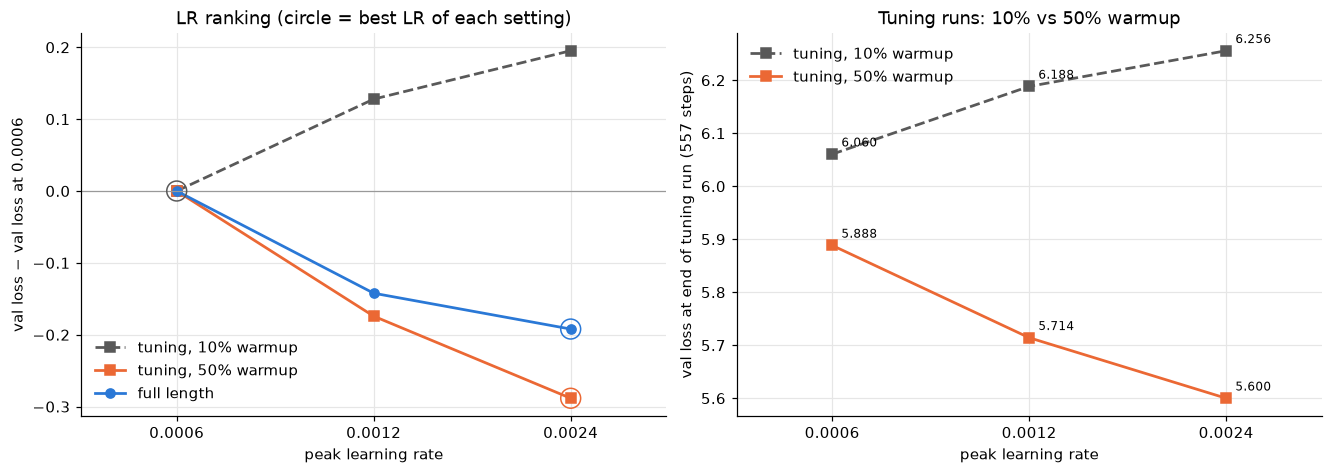

,"tuning, 10% warmup","tuning, 50% warmup",full length
0.0012 − 0.0006,0.128,-0.174,-0.142
0.0024 − 0.0006,0.195,-0.288,-0.192


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)
ax = axes[0]
for g in table:
    rel = table[g] - table.loc[min(LRS), g]
    ax.plot(LRS, rel, label=g, linewidth=1.8, **STYLE[g])
    ax.scatter(rel.idxmin(), rel.min(), s=170, facecolors="none", edgecolors=STYLE[g]["color"], zorder=4)
ax.axhline(0, color="0.6", linewidth=0.8)
ax.set_ylabel(f"val loss − val loss at {min(LRS):g}")
ax.set_title("LR ranking (circle = best LR of each setting)")
ax.legend(loc="lower left")
ax = axes[1]
for g in ["tuning, 10% warmup", "tuning, 50% warmup"]:
    ax.plot(LRS, table[g], label=g, linewidth=1.8, **STYLE[g])
    for lr, v in table[g].items():
        ax.annotate(f"{v:.3f}", (lr, v), xytext=(6, 5), textcoords="offset points", fontsize=8)
ax.set_ylabel("val loss at end of tuning run (557 steps)")
ax.set_title("Tuning runs: 10% vs 50% warmup")
ax.legend(loc="upper left")
for ax in axes:
    ax.set_xscale("log", base=2)
    ax.set_xticks(LRS, [f"{lr:g}" for lr in LRS])
    ax.minorticks_off()
    ax.set_xlim(min(LRS) / 1.4, max(LRS) * 1.4)
    ax.set_xlabel("peak learning rate")
plt.show()

gaps = pd.DataFrame({g: table[g] - table.loc[min(LRS), g] for g in table}).drop(index=min(LRS))
gaps.index = [f"{lr:g} − {min(LRS):g}" for lr in gaps.index]
gaps.round(3)

## Loss curves and LR schedules

Top: val loss (evals at 0, 250, 500, 557) and train loss (every 10 steps, smoothed) of the six tuning runs.
Bottom: the logged LR. Both schedules have the same peak and the same area; the 10% one front-loads it.

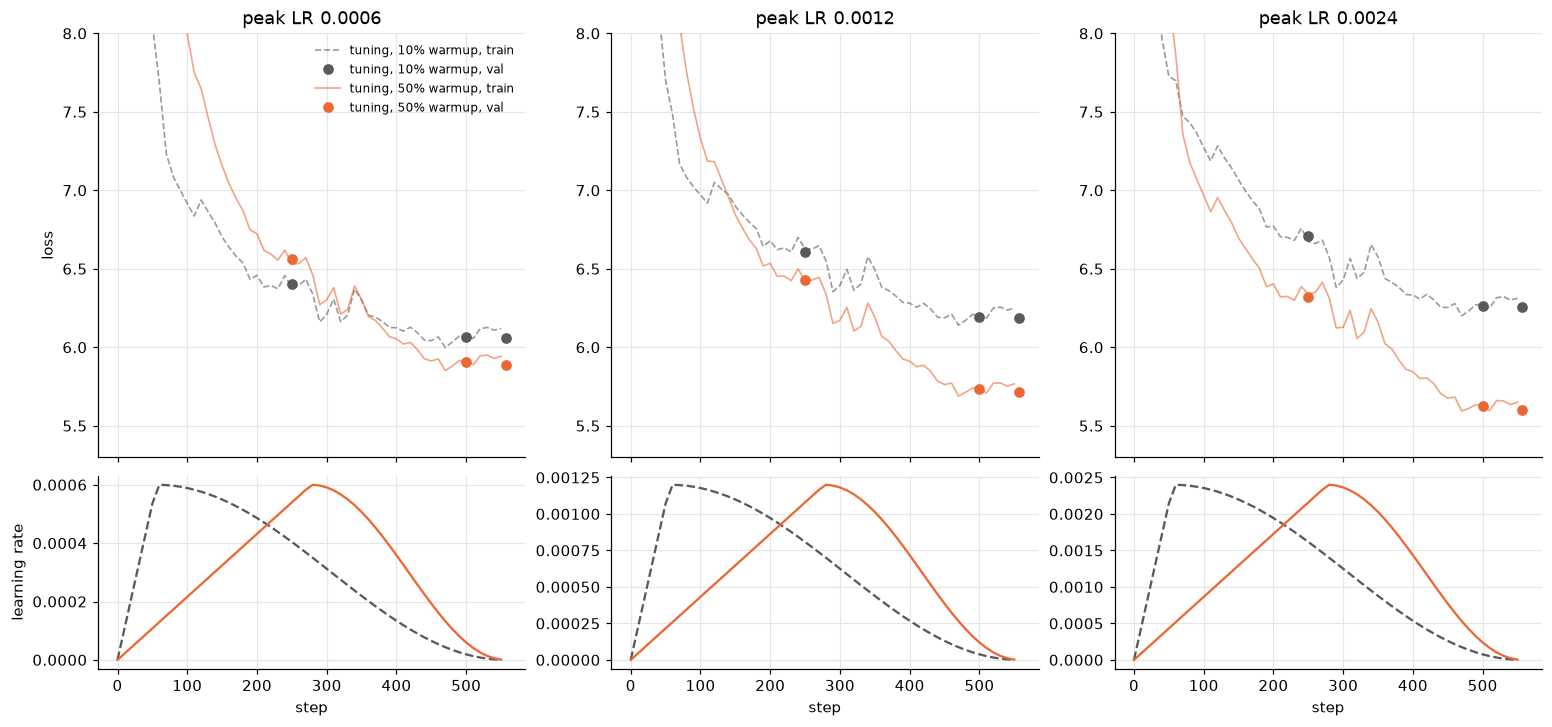

val loss @ 250  val loss @ 500  val loss @ 557
lr     setting                                                           
0.0006 tuning, 10% warmup           6.400           6.065           6.060
       tuning, 50% warmup           6.561           5.903           5.888
0.0012 tuning, 10% warmup           6.606           6.196           6.188
       tuning, 50% warmup           6.430           5.733           5.714
0.0024 tuning, 10% warmup           6.711           6.262           6.256
       tuning, 50% warmup           6.321           5.626           5.600

In [5]:
def smooth(s, w=5):
    return s.rolling(w, center=True, min_periods=1).mean()


fig, axes = plt.subplots(2, len(LRS), figsize=(14, 6.5), sharex=True, constrained_layout=True,
                         gridspec_kw={"height_ratios": [2.2, 1]})
for j, lr in enumerate(LRS):
    for g in ["tuning, 10% warmup", "tuning, 50% warmup"]:
        n, st = name[g][lr], STYLE[g]
        tr, ev = load(n, "train.csv"), load(n)
        axes[0, j].plot(tr["iter"], smooth(tr["loss"]), color=st["color"], linestyle=st["linestyle"], linewidth=1.1,
                        alpha=0.6, label=f"{g}, train")
        axes[0, j].plot(ev["iter"], ev["val_loss"], color=st["color"], marker="o", linestyle="none", label=f"{g}, val")
        axes[1, j].plot(tr["iter"], tr["lr"], color=st["color"], linestyle=st["linestyle"], linewidth=1.5)
    axes[0, j].set_title(f"peak LR {lr:g}")
    axes[0, j].set_ylim(5.3, 8)
    axes[1, j].set_xlabel("step")
axes[0, 0].set_ylabel("loss")
axes[1, 0].set_ylabel("learning rate")
axes[0, 0].legend(loc="upper right", fontsize=8)
plt.show()

rows = []
for lr in LRS:
    for g in ["tuning, 10% warmup", "tuning, 50% warmup"]:
        ev = load(name[g][lr]).set_index("iter")
        rows.append({"lr": lr, "setting": g, **{f"val loss @ {i}": ev.loc[i, "val_loss"] for i in ev.index if i > 0}})
pd.DataFrame(rows).set_index(["lr", "setting"]).round(3)

## Reading

- Ranking: with 50% warmup the tuning sweep orders the three LRs 2.4e-3 < 1.2e-3 < 6e-4, the same order as the
  full-length runs; with 10% warmup it was the reverse (6e-4 best). By the pre-declared rule, the short warmup
  explains the low-LR bias at SP 256x64.
- The longer warmup lowered the tuning loss at every LR, most at the highest LR, so the fast 56-step ramp hurt
  all three runs and the high-LR ones the most.
- Gap sizes do not match: at full length 2.4e-3 is only a little better than 1.2e-3, while with 50% warmup the
  difference is larger. The longer warmup fixes the ranking, not the size of the effect.
- Caveats: one shape, one parameterization, three LRs, one seed (run-to-run noise was measured only at full
  length at 512x16, SD ≈ 0.008; the differences here are an order of magnitude larger). The 50% schedule also
  keeps more LR late in the run, so the precise statement is "the compressed early schedule penalizes high peak LRs",
  not "warmup length in steps". 2.4e-3 is the top of the tested range, so the 50%-warmup optimum is not bracketed either.